In [33]:
from pathlib import Path
import pandas as pd

# Notebook runs from notebooks/, so results is one level up
results_dir = Path("../results").resolve()
output_dir = results_dir / "processed_csvs"
output_file = output_dir / "processed_ki67.csv"

# Find every CSV under results/ recursively, excluding the final output file if it already exists
csv_files = sorted(
    csv_path
    for csv_path in results_dir.rglob("*.csv")
    if csv_path.resolve() != output_file.resolve()
)

if not csv_files:
    raise FileNotFoundError(f"No CSV files found under {results_dir}")

# Read and merge all CSV files
merged_df = pd.concat((pd.read_csv(csv_file) for csv_file in csv_files), ignore_index=True)

# Ensure output directory exists and save merged CSV
output_dir.mkdir(parents=True, exist_ok=True)
merged_df.to_csv(output_file, index=False)

print(f"Found results directory: {results_dir}")
print(f"Merged {len(csv_files)} CSV files into: {output_file}")
print(f"Merged dataframe shape: {merged_df.shape}")
merged_df.head()

Found results directory: C:\Users\adiez_cmic\github_repos\margrecs_alginate\results
Merged 33 CSV files into: C:\Users\adiez_cmic\github_repos\margrecs_alginate\results\processed_csvs\processed_ki67.csv
Merged dataframe shape: (86329, 31)


,lif_container_id,lif_image_name,label,centroid-0,centroid-1,centroid-2,area,area_bbox,area_filled,equivalent_diameter_area,...,F-Actin_min_int,F-Actin_max_int,F-Actin_std_int,F-Actin_sum_int,ki67_mean_int,ki67_min_int,ki67_max_int,ki67_std_int,ki67_sum_int,input_img_shape
0,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,1,8.758796,11.897715,6.305767,2757.0,9025.0,2757.0,17.397201,...,7.0,219.0,23.618313,88893.0,13.816830,0.0,69.0,11.534976,38093.0,"[107, 1024, 1024]"
1,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,2,27.742657,23.812587,4.513986,1430.0,6120.0,1430.0,13.978025,...,4.0,15.0,1.868374,11083.0,1.820280,0.0,13.0,2.232752,2603.0,"[107, 1024, 1024]"
2,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,3,7.442077,25.631158,6.420107,1502.0,5580.0,1502.0,14.208790,...,6.0,87.0,8.623981,30722.0,9.438748,0.0,45.0,6.745708,14177.0,"[107, 1024, 1024]"
3,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,4,31.826923,32.365385,0.846154,52.0,336.0,52.0,4.630930,...,4.0,8.0,1.051028,303.0,1.307692,0.0,8.0,1.834902,68.0,"[107, 1024, 1024]"
4,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,5,1.889573,21.681856,6.771346,2436.0,5040.0,2436.0,16.693967,...,6.0,255.0,34.830868,124966.0,19.988916,0.0,74.0,12.105833,48693.0,"[107, 1024, 1024]"


In [34]:
import numpy as np

# Create 'condition' column
def extract_condition(container_id):
    cid = str(container_id).lower()
    if "perfusion" in cid:
        return "perfusion"
    elif "static" in cid:
        return "static"
    else:
        return "undefined"

merged_df["condition"] = merged_df["lif_container_id"].apply(extract_condition)

# Create 'day' column
def extract_day(image_name):
    name = str(image_name)
    if any(tag in name for tag in ["d3-", "D3-"]):
        return 3
    elif any(tag in name for tag in ["d7-", "D7-"]):
        return 7
    elif any(tag in name for tag in ["d14-", "D14-"]):
        return 14
    else:
        return np.nan  # could be left blank if not found

merged_df["day"] = merged_df["lif_image_name"].apply(extract_day)

In [35]:
# Filter out rows where area is below 500 or above 6500
filtered_df = merged_df[(merged_df["area"] >= 500) & (merged_df["area"] <= 6500)]

# Percentile-based filtering for ki67_mean_int (between 1st and 99th percentiles)
ki67_lower = np.percentile(filtered_df["ki67_mean_int"], 1)
ki67_upper = np.percentile(filtered_df["ki67_mean_int"], 99)

filtered_df = filtered_df[
    (filtered_df["ki67_mean_int"] >= ki67_lower) &
    (filtered_df["ki67_mean_int"] <= ki67_upper)
]

# Replace merged_df with filtered_df so all downstream cells use the filtered data
merged_df = filtered_df

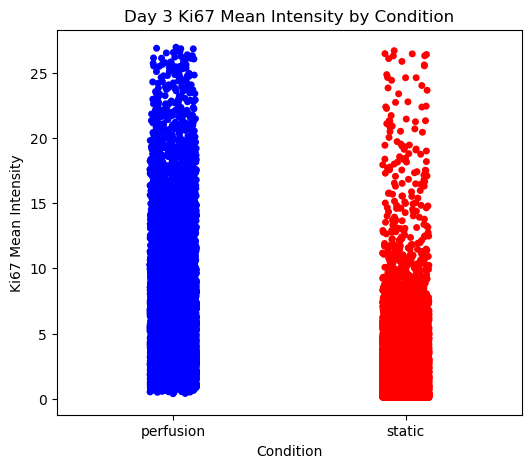

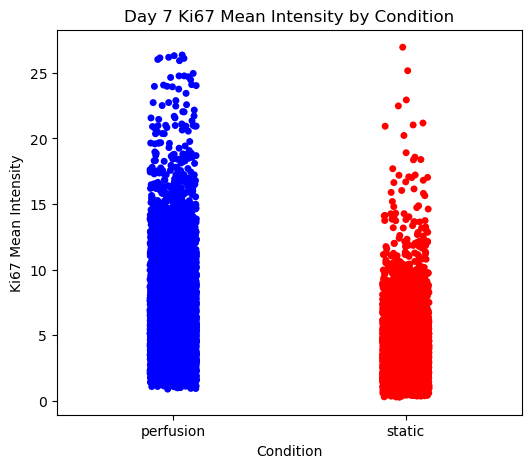

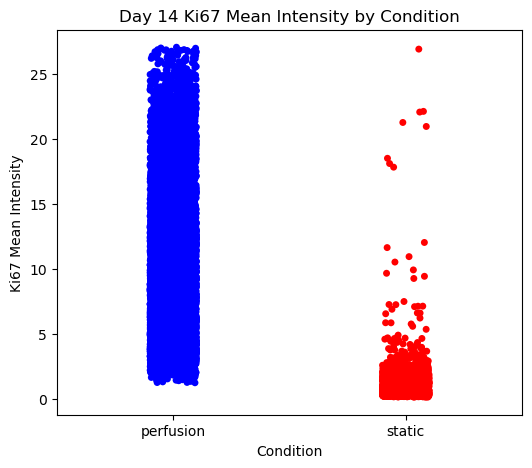

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

# Loop over days 3, 7, and 14 and produce the strip plots for each day
for day in [3, 7, 14]:
    df_day = merged_df[merged_df["day"] == day]

    plt.figure(figsize=(6, 5))
    ax = sns.stripplot(
        data=df_day,
        x="condition",
        y="ki67_mean_int",
        hue="condition",
        palette={"static": "red", "perfusion": "blue"},
        dodge=False
    )
    ax.set_title(f"Day {day} Ki67 Mean Intensity by Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Ki67 Mean Intensity")
    plt.show()

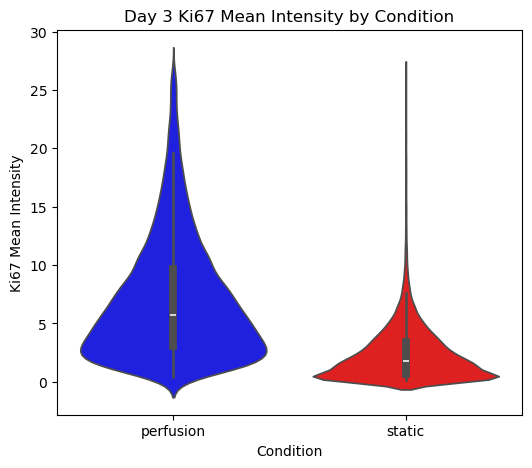

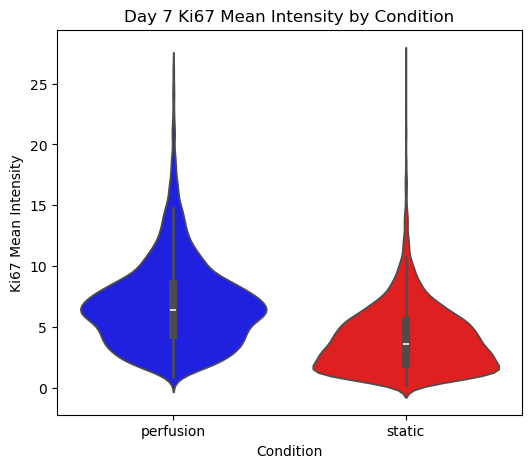

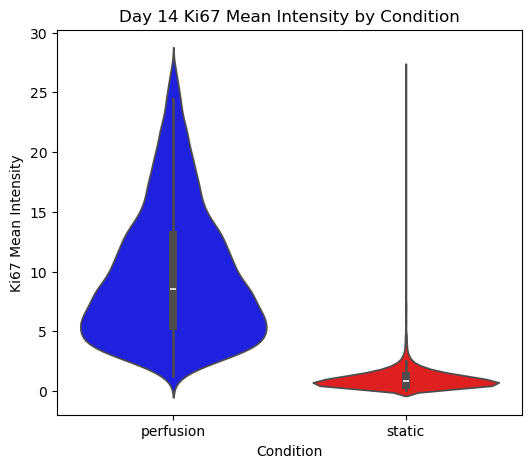

In [37]:
# Loop over days 3, 7, and 14 and produce the violin plots for each day
for day in [3, 7, 14]:
    df_day = merged_df[merged_df["day"] == day]

    plt.figure(figsize=(6, 5))
    ax = sns.violinplot(
        data=df_day,
        x="condition",
        y="ki67_mean_int",
        hue="condition",
        palette={"static": "red", "perfusion": "blue"},
        legend=False,
        dodge=False
    )
    ax.set_title(f"Day {day} Ki67 Mean Intensity by Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Ki67 Mean Intensity")
    plt.show()

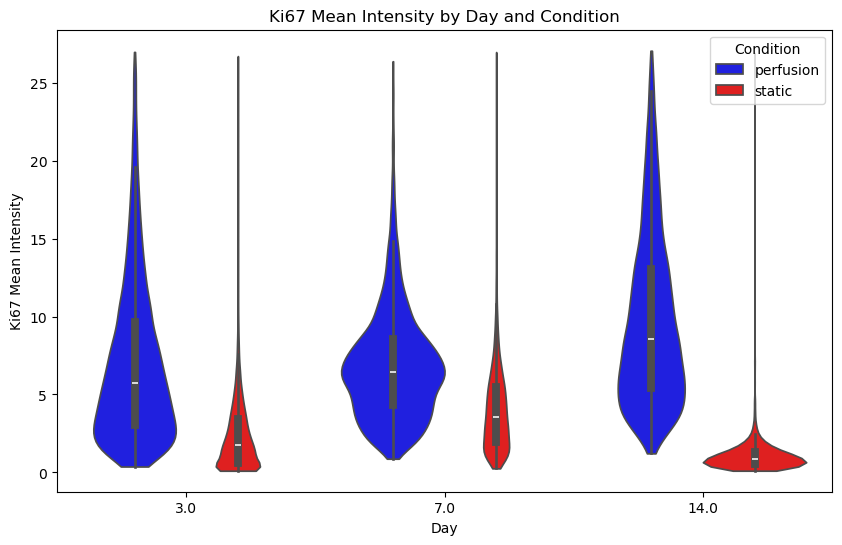

In [38]:
# Plot violin plots for days 3, 7, and 14 side by side, grouping by day
plt.figure(figsize=(10, 6))
ax = sns.violinplot(
    data=merged_df[merged_df["day"].isin([3, 7, 14])],
    x="day",
    y="ki67_mean_int",
    hue="condition",
    palette={"static": "red", "perfusion": "blue"},
    dodge=True,
    cut=0
)
ax.set_title("Ki67 Mean Intensity by Day and Condition")
ax.set_xlabel("Day")
ax.set_ylabel("Ki67 Mean Intensity")
plt.legend(title="Condition")
plt.show()

In [40]:
def classify_ki67_status(
    props_df: "pd.DataFrame",
    feature_columns: list = ['ki67_mean_int', 'ki67_sum_int']
) -> "pd.DataFrame":
    """
    Classify nuclei as Ki67 positive (1) or negative (0) using k-means clustering
    on the specified ki67 intensity features.

    Args:
        props_df (pd.DataFrame): DataFrame containing per-nucleus features.
        feature_columns (list, optional): List of feature column names to use for clustering.
            Default is ['ki67_mean_int', 'ki67_sum_int'].

    Returns:
        pd.DataFrame: The input DataFrame with an additional column:
            - 'ki67_status': 1 for Ki67 positive, 0 for Ki67 negative

    Notes:
        - Features are standardized before clustering.
        - The cluster with HIGHER mean 'ki67_mean_int' is mapped to Ki67 positive (1).
    """

    from sklearn.preprocessing import StandardScaler
    from sklearn.cluster import KMeans
    import numpy as np

    # Select features for clustering
    features = props_df[feature_columns].values

    # Standardize features to have mean=0, std=1
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)

    # Perform k-means clustering (k=2)
    kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
    cluster_ids = kmeans.fit_predict(features_scaled)

    # Add cluster assignments to DataFrame
    props_df = props_df.copy()
    props_df['ki67_cluster_id'] = cluster_ids

    # Determine which cluster has higher ki67_mean_int
    cluster_means = (
        props_df.groupby('ki67_cluster_id')['ki67_mean_int']
        .mean()
        .sort_values()
    )
    ordered_cluster_ids = cluster_means.index.tolist()
    ki67_status_map = {
        ordered_cluster_ids[0]: 0,  # lower mean: negative
        ordered_cluster_ids[1]: 1   # higher mean: positive
    }
    props_df['ki67_status'] = props_df['ki67_cluster_id'].map(ki67_status_map)
    props_df.drop(columns=['ki67_cluster_id'], inplace=True)

    return props_df

In [44]:
ki67_df = classify_ki67_status(merged_df, feature_columns=['ki67_mean_int'])

In [46]:
import pandas as pd
import plotly.express as px

# Calculate percentage of Ki67 positive cells per lif_image_name, also including condition and day.
ki67_perc_df = (
    ki67_df.groupby(['lif_image_name', 'condition', 'day'])['ki67_status']
    .agg(
        n_cells='count',
        n_ki67_pos='sum'
    )
    .reset_index()
)
ki67_perc_df['ki67_pos_pct'] = 100 * ki67_perc_df['n_ki67_pos'] / ki67_perc_df['n_cells']

# Plot with Plotly for interactive hover (lif_image_name visible)
fig = px.strip(
    ki67_perc_df,
    x="day",
    y="ki67_pos_pct",
    color="condition",
    hover_data=["lif_image_name", "n_cells", "n_ki67_pos"],
    stripmode="overlay",
)
fig.update_traces(jitter=0.4, marker=dict(size=9, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(
    yaxis_title='Percentage of Ki67 Positive Cells',
    xaxis_title='Day',
    title='Percentage of Ki67+ Cells per Image',
    width=1200,
    height=600,
    xaxis_tickangle=-45
)
fig.show()